# Separating ambiguity from ordinary risk

This native Julia companion preserves the original equations, supplied probability laws, approved NASDAQ observations, calendar grouping, population moments, bins, weights, comparisons and assertions. Both tails remain explicit. Native figures use the requested dark theme; Julia tables and figures are saved under `outputs/julia`.

## Risk Inside One Probability Law

Let the possible returns be \(x_1,\ldots,x_K\), and let one probability law assign probability \(p_k\) to outcome \(x_k\). Its mean return is

$$
\mu=\sum_{k=1}^{K}p_kx_k,
$$

and its return variance is

$$
\sigma^2=\sum_{k=1}^{K}p_k(x_k-\mu)^2.
$$

Here, \(K\) is the number of mutually exclusive outcomes; \(x_k\) is outcome \(k\); \(p_k\) is its probability; \(\mu\) is the probability weighted mean; and \(\sigma^2\) measures dispersion of outcomes around that mean. Risk is present when one known law assigns positive probability to different outcomes.

## Ambiguity Across Probability Laws

Suppose there are \(J\) possible probability laws. Law \(j\) assigns probability \(p_{j,k}\) to outcome \(k\), and the law receives prior weight \(q_j\). The mean probability of outcome \(k\) is

$$
\bar p_k=\sum_{j=1}^{J}q_jp_{j,k},
$$

and the population variance of that probability is

$$
v_k=\sum_{j=1}^{J}q_j(p_{j,k}-\bar p_k)^2.
$$

Here, \(J\) is the number of supplied laws; \(q_j\geq0\) is the weight on law \(j\), with \(\sum_jq_j=1\); \(p_{j,k}\) is the probability of outcome \(k\) under law \(j\); \(\bar p_k\) is the prior weighted mean probability; and \(v_k\) measures disagreement about that probability. Ambiguity concerns variation across the laws, not variation in the outcomes under one law.

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"0.6.2"
configure_plots!()
paths = output_paths("04_probability_ambiguity");
using CSV, Printf
using RiskLabAI.Features: probability_ambiguity, normal_prior_bin_probabilities

function load_public_data()
    data_path = dataset_path("fred_nasdaq")
    @assert isfile(data_path)
    raw = CSV.read(data_path,DataFrame;missingstring=["", "."])
    data = dropmissing(raw,:NASDAQCOM)
    sort!(data,:observation_date)
    rename!(data,:observation_date=>"Date",:NASDAQCOM=>"NASDAQ Composite")
    data.Date = Date.(data.Date)
    prices = data[!,"NASDAQ Composite"]
    data[!,"Daily log return"] = vcat(NaN,log.(prices[2:end]./prices[1:end-1]))
    data.Year = year.(data.Date)
    data.Month = month.(data.Date)
    return data
end

function monthly_moments(data)
    returns = data[isfinite.(data[!,"Daily log return"]),:]
    return combine(groupby(returns,[:Year,:Month];sort=true),"Daily log return"=>mean=>:Mean,"Daily log return"=>(values->std(values;corrected=false))=>:Standard_deviation,"Daily log return"=>length=>:Observations)
end

normal_edges(width) = collect(range(-.06,.06;length=round(Int,.12/width)+1))
percent_label(value) = @sprintf("%g%%",100value)
bin_labels(edges) = vcat("Below "*percent_label(first(edges)),[percent_label(left)*" to "*percent_label(right) for (left,right) in zip(edges[1:end-1],edges[2:end])],"Above "*percent_label(last(edges)))


bin_labels (generic function with 1 method)

In [2]:
outcomes = collect(-2.:2.)
known_narrow = repeat([.05 .15 .60 .15 .05],3,1)
known_wide = repeat([.30 .15 .10 .15 .30],3,1)
shifting_center = [.55 .30 .10 .04 .01; .05 .15 .60 .15 .05; .01 .04 .10 .30 .55]
changing_tails = [.05 .15 .60 .15 .05; .20 .25 .10 .25 .20; .45 .05 .00 .05 .45]
weights = fill(1/3,3)
prior_table = DataFrame(changing_tails,["Return "*@sprintf("%g",value) for value in outcomes])
insertcols!(prior_table,1,"Supplied law"=>["Law 1","Law 2","Law 3"])
save_table(prior_table,paths,"discrete_prior_example";caption="Three supplied probability laws over five return outcomes.",label="tab:chapter5-discrete-prior-example")
case_rows = NamedTuple[]
for (name,probabilities) in [("Known narrow law",known_narrow),("Known wide law",known_wide),("Changing center",shifting_center),("Changing tails",changing_tails)]
    mean_probability = vec(weights'*probabilities)
    expected_return = dot(mean_probability,outcomes)
    expected_return = abs(expected_return)<1e-12 ? 0. : expected_return
    return_variance = dot(mean_probability,(outcomes.-expected_return).^2)
    ambiguity = probability_ambiguity(probabilities;prior_weights=weights).unscaled
    push!(case_rows,(;name,expected_return,return_variance,ambiguity))
end
case_frame = DataFrame(case_rows)
rename!(case_frame,["Case","Mean return","Return variance","Probability ambiguity"])
save_table(case_frame,paths,"risk_ambiguity_cases";caption="Return risk and probability ambiguity in four supplied examples.",label="tab:chapter5-risk-ambiguity-cases")
law_rows = [(;law="Law "*string(j),outcome=outcomes[k],probability=changing_tails[j,k]) for j in 1:3 for k in 1:5]
law_frame = DataFrame(law_rows)
rename!(law_frame,["Supplied law","Return outcome","Probability"])
save_data(law_frame,paths,"supplied_probability_laws")
save_data(case_frame,paths,"risk_ambiguity_cases");


Row,Supplied law,Return -2,Return -1,Return 0,Return 1,Return 2
,String,Float64,Float64,Float64,Float64,Float64
1,Law 1,0.05,0.15,0.6,0.15,0.05
2,Law 2,0.2,0.25,0.1,0.25,0.2
3,Law 3,0.45,0.05,0.0,0.05,0.45


Row,Case,Mean return,Return variance,Probability ambiguity
,String,Float64,Float64,Float64
1,Known narrow law,0.0,0.7,0.0
2,Known wide law,0.0,2.7,0.0
3,Changing center,0.0,1.95333,0.0430689
4,Changing tails,0.0,2.16667,0.0307778


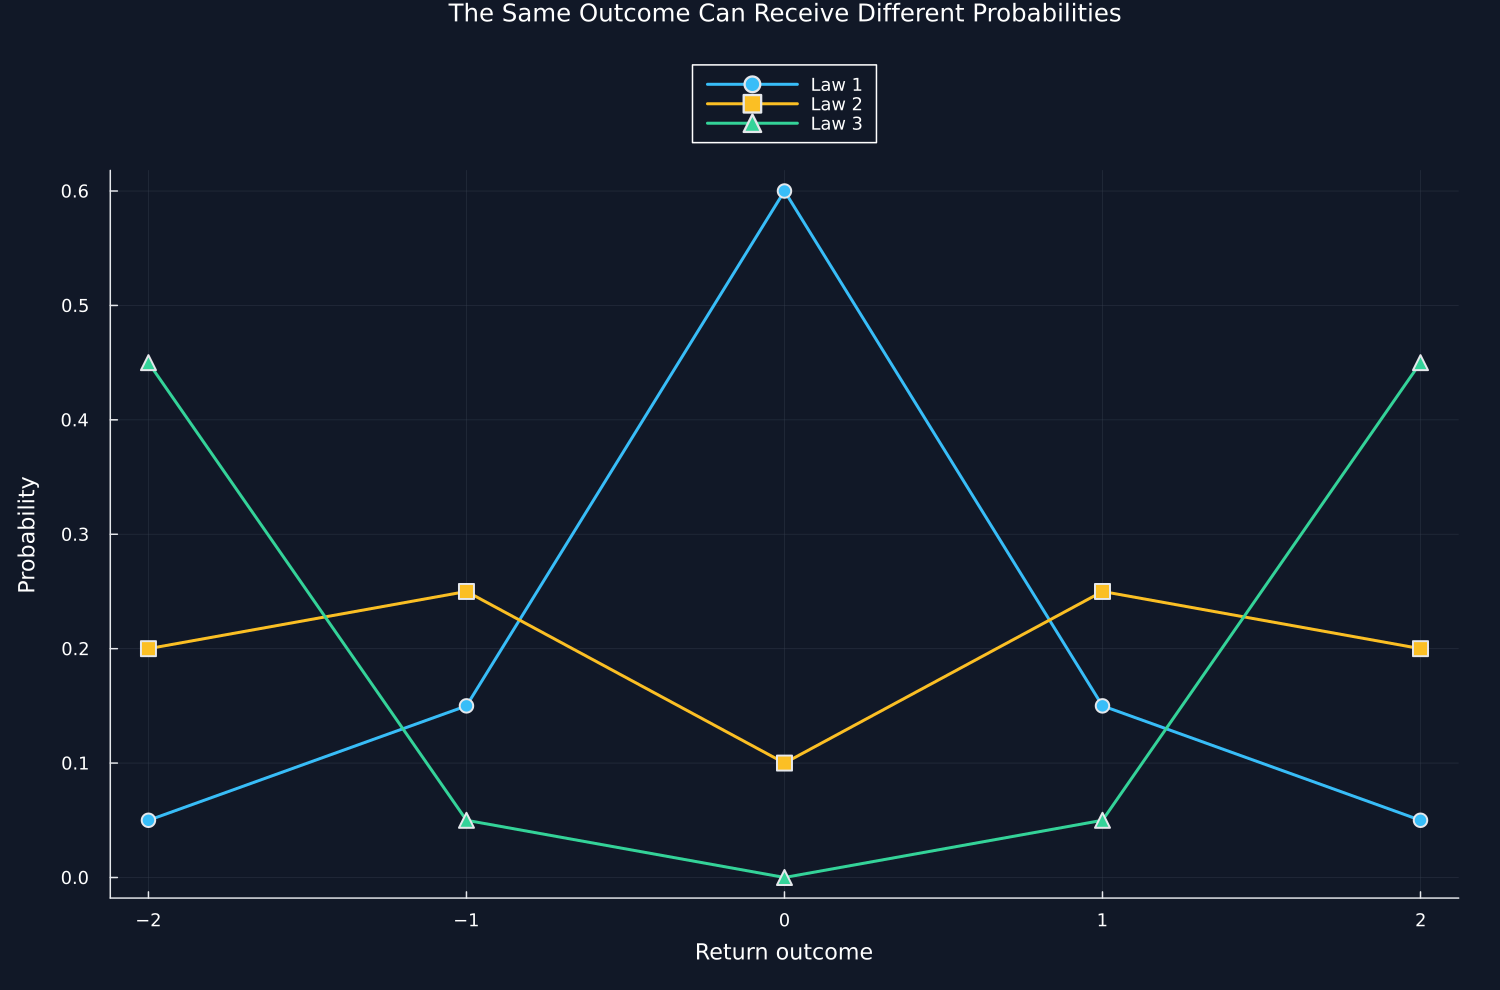

In [3]:
figure = plot(;xlabel="Return outcome",ylabel="Probability",title="The Same Outcome Can Receive Different Probabilities",xticks=outcomes,legend=:outertop,size=(1000,660))
for (j,color,marker) in zip(1:3,[palette.cyan,palette.amber,palette.green],[:circle,:square,:utriangle])
    plot!(figure,outcomes,changing_tails[j,:];color,marker,markersize=5,label="Law "*string(j))
end
save_figure(figure,paths,"supplied_probability_laws")


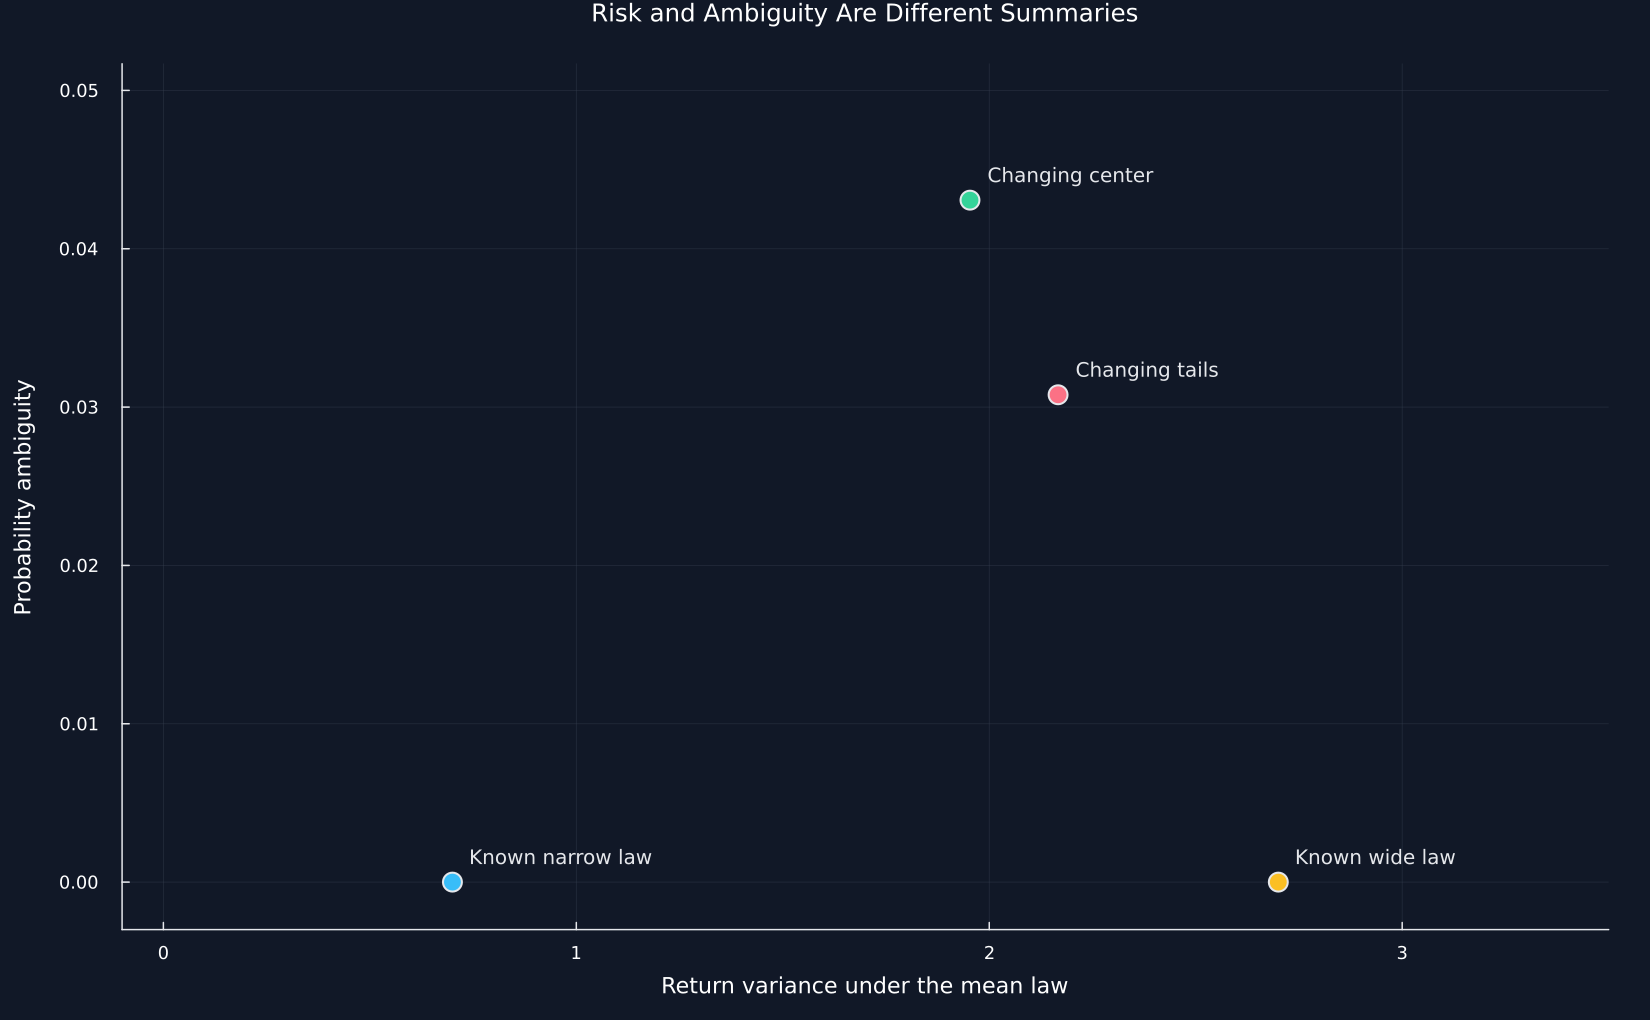

In [4]:
figure = plot(;xlabel="Return variance under the mean law",ylabel="Probability ambiguity",title="Risk and Ambiguity Are Different Summaries",legend=false,xlims=(-.1,3.5),ylims=(-.003,1.2*maximum(case_frame[!,"Probability ambiguity"])),size=(1100,680))
for (row,color) in zip(eachrow(case_frame),[palette.cyan,palette.amber,palette.green,palette.rose])
    scatter!(figure,[row["Return variance"]],[row["Probability ambiguity"]];color,markersize=7,label=false)
    annotate!(figure,row["Return variance"]+.045,row["Probability ambiguity"]+.0016,text(row.Case,9,palette.text,:left))
end
save_figure(figure,paths,"risk_and_ambiguity_examples")


## Verifying the finite ambiguity measure

The finite supplied-prior ambiguity measure is

$$
A=\sum_{k=1}^{K}\bar p_kv_k.
$$

Here, \(A\) is the unscaled ambiguity measure; \(\bar p_k\) is the mean probability of outcome bin \(k\); and \(v_k\) is the variance of that probability across supplied laws. Every term is nonnegative. The measure is therefore nonnegative, and it is zero when all positively weighted laws agree on every bin.

The variance in each bin also has the pairwise form

$$
v_k=\frac{1}{2}\sum_{i=1}^{J}\sum_{j=1}^{J}q_iq_j(p_{i,k}-p_{j,k})^2.
$$

Here, \(i\) and \(j\) identify two supplied laws. The squared difference records their disagreement in bin \(k\), while \(q_iq_j/2\) supplies the pair weight without double counting. This identity provides an independent calculation of the measure.

In [5]:
probabilities = [.2 .8; .6 .4; 1. 0.]
prior_weights = [.2,.3,.5]
result = probability_ambiguity(probabilities;prior_weights,bin_width=.002)
mean_probability = vec(prior_weights'*probabilities)
direct_variance = vec(prior_weights'*(probabilities.-mean_probability').^2)
direct_value = dot(mean_probability,direct_variance)
pairwise_variance = [.5*sum(prior_weights[i]*prior_weights[j]*(probabilities[i,k]-probabilities[j,k])^2 for i in 1:3,j in 1:3) for k in 1:2]
pairwise_value = dot(mean_probability,pairwise_variance)
permuted_value = probability_ambiguity(reverse(probabilities;dims=1);prior_weights=reverse(prior_weights)).unscaled
identical_value = probability_ambiguity(fill(.5,3,2)).unscaled
extreme_value = probability_ambiguity([0. 1.;1. 0.]).unscaled
checks = DataFrame("Check"=>["Library and direct enumeration agree","Library and pairwise identity agree","Prior ordering leaves the value unchanged","Identical laws give zero ambiguity","Two opposite certain laws give one quarter","Scaled value follows the stated relation"],"Calculated difference"=>[abs(result.unscaled-direct_value),abs(result.unscaled-pairwise_value),abs(result.unscaled-permuted_value),abs(identical_value),abs(extreme_value-.25),abs(result.scaled-result.unscaled/(.002*.998))],"Result"=>fill("Pass",6))
@assert all(checks[!,"Calculated difference"].<1e-12)
save_table(checks,paths,"finite_formula_checks";caption="Independent checks of the finite ambiguity formula.",label="tab:chapter5-finite-formula-checks")
boundaries = DataFrame("Case"=>["One known wide law","Three identical laws","Two opposite certain laws"],"Return variance"=>[dot(known_wide[1,:],outcomes.^2),dot(known_narrow[1,:],outcomes.^2),1.],"Probability ambiguity"=>[probability_ambiguity(known_wide[1:1,:]).unscaled,identical_value,extreme_value])
save_table(boundaries,paths,"ambiguity_boundary_cases";caption="Boundary cases that separate return dispersion from probability disagreement.",label="tab:chapter5-ambiguity-boundary-cases")


Row,Check,Calculated difference,Result
,String,Float64,String
1,Library and direct enumeration agree,0.0,Pass
2,Library and pairwise identity agree,1.38778e-17,Pass
3,Prior ordering leaves the value unchanged,1.38778e-17,Pass
4,Identical laws give zero ambiguity,0.0,Pass
5,Two opposite certain laws give one quarter,0.0,Pass
6,Scaled value follows the stated relation,0.0,Pass


Row,Case,Return variance,Probability ambiguity
,String,Float64,Float64
1,One known wide law,2.7,0.0
2,Three identical laws,0.7,0.0
3,Two opposite certain laws,1.0,0.25
